In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

In [25]:
df = pd.read_csv("dermatology_database_1.csv")

# Replace '?' with NaN
df = df.replace("?", np.nan)

print("Shape of dataset:", df.shape)
df.head()

Shape of dataset: (366, 35)


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_granular_layer,vacuolisation_damage_basal_layer,spongiosis,saw_tooth_appearance_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_mononuclear_infiltrate,band_like_infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3


In [6]:
display(df.tail())

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_granular_layer,vacuolisation_damage_basal_layer,spongiosis,saw_tooth_appearance_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_mononuclear_infiltrate,band_like_infiltrate,age,class
361,2,1,1,0,1,0,0,0,0,0,...,0,0,1,0,0,0,2,0,25,4
362,3,2,1,0,1,0,0,0,0,0,...,1,0,1,0,0,0,2,0,36,4
363,3,2,2,2,3,2,0,2,0,0,...,0,3,0,3,0,0,2,3,28,3
364,2,1,3,1,2,3,0,2,0,0,...,0,2,0,1,0,0,2,3,50,3
365,3,2,2,0,0,0,0,0,3,3,...,2,0,0,0,0,0,3,0,35,1


In [7]:
print("Column names:")
print(df.columns.tolist())

Column names:
['erythema', 'scaling', 'definite_borders', 'itching', 'koebner_phenomenon', 'polygonal_papules', 'follicular_papules', 'oral_mucosal_involvement', 'knee_and_elbow_involvement', 'scalp_involvement', 'family_history', 'melanin_incontinence', 'eosinophils_infiltrate', 'PNL_infiltrate', 'fibrosis_papillary_dermis', 'exocytosis', 'acanthosis', 'hyperkeratosis', 'parakeratosis', 'clubbing_rete_ridges', 'elongation_rete_ridges', 'thinning_suprapapillary_epidermis', 'spongiform_pustule', 'munro_microabcess', 'focal_hypergranulosis', 'disappearance_granular_layer', 'vacuolisation_damage_basal_layer', 'spongiosis', 'saw_tooth_appearance_retes', 'follicular_horn_plug', 'perifollicular_parakeratosis', 'inflammatory_mononuclear_infiltrate', 'band_like_infiltrate', 'age', 'class']


In [8]:
# summary statistics

print("Mean:")
display(df.mean(numeric_only=True))

print("\nMedian:")
display(df.median(numeric_only=True))

print("\nStandard Deviation:")
display(df.std(numeric_only=True))

print("\nMinimum:")
display(df.min(numeric_only=True))

print("\nMaximum:")
display(df.max(numeric_only=True))

Mean:


,0
erythema,2.068306
scaling,1.795082
definite_borders,1.549180
itching,1.366120
koebner_phenomenon,0.633880
polygonal_papules,0.448087
follicular_papules,0.166667
oral_mucosal_involvement,0.377049
knee_and_elbow_involvement,0.614754
scalp_involvement,0.519126



Median:


,0
erythema,2.0
scaling,2.0
definite_borders,2.0
itching,1.0
koebner_phenomenon,0.0
polygonal_papules,0.0
follicular_papules,0.0
oral_mucosal_involvement,0.0
knee_and_elbow_involvement,0.0
scalp_involvement,0.0



Standard Deviation:


,0
erythema,0.664753
scaling,0.701527
definite_borders,0.907525
itching,1.138299
koebner_phenomenon,0.908016
polygonal_papules,0.957327
follicular_papules,0.570588
oral_mucosal_involvement,0.834147
knee_and_elbow_involvement,0.982979
scalp_involvement,0.905639



Minimum:


,0
erythema,0
scaling,0
definite_borders,0
itching,0
koebner_phenomenon,0
polygonal_papules,0
follicular_papules,0
oral_mucosal_involvement,0
knee_and_elbow_involvement,0
scalp_involvement,0



Maximum:


,0
erythema,3
scaling,3
definite_borders,3
itching,3
koebner_phenomenon,3
polygonal_papules,3
follicular_papules,3
oral_mucosal_involvement,3
knee_and_elbow_involvement,3
scalp_involvement,3


In [29]:
# checking missing values

print("Total missing values in features:", X.isnull().sum().sum())

print("\nMissing values by column:")
display(
    X.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

Total missing values in features: 0

Missing values by column:


,Missing Values
erythema,0
scaling,0
definite_borders,0
itching,0
koebner_phenomenon,0
polygonal_papules,0
follicular_papules,0
oral_mucosal_involvement,0
knee_and_elbow_involvement,0
scalp_involvement,0


In [30]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 8


In [31]:
# checking for duplicates

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [32]:
# detecting outliers using IQR

numeric_features = df.drop(columns=["class"]).select_dtypes(
    include=np.number
).columns

outlier_summary = []

for column in numeric_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_summary.append([
        column,
        Q1,
        Q3,
        IQR,
        lower_bound,
        upper_bound,
        len(outliers)
    ])

outlier_df = pd.DataFrame(
    outlier_summary,
    columns=[
        "Feature",
        "Q1",
        "Q3",
        "IQR",
        "Lower Bound",
        "Upper Bound",
        "Outlier Count"
    ]
)

display(outlier_df)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,erythema,2.0,2.0,0.0,2.0,2.0,151
1,scaling,1.0,2.0,1.0,-0.5,3.5,0
2,definite_borders,1.0,2.0,1.0,-0.5,3.5,0
3,itching,0.0,2.0,2.0,-3.0,5.0,0
4,koebner_phenomenon,0.0,1.0,1.0,-1.5,2.5,18
5,polygonal_papules,0.0,0.0,0.0,0.0,0.0,69
6,follicular_papules,0.0,0.0,0.0,0.0,0.0,33
7,oral_mucosal_involvement,0.0,0.0,0.0,0.0,0.0,67
8,knee_and_elbow_involvement,0.0,1.0,1.0,-1.5,2.5,23
9,scalp_involvement,0.0,1.0,1.0,-1.5,2.5,16


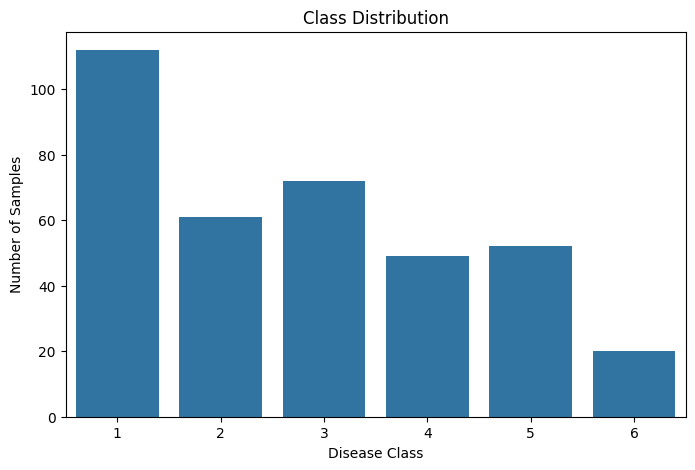

In [33]:
# class distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="class"
)

plt.title("Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Samples")

plt.show()

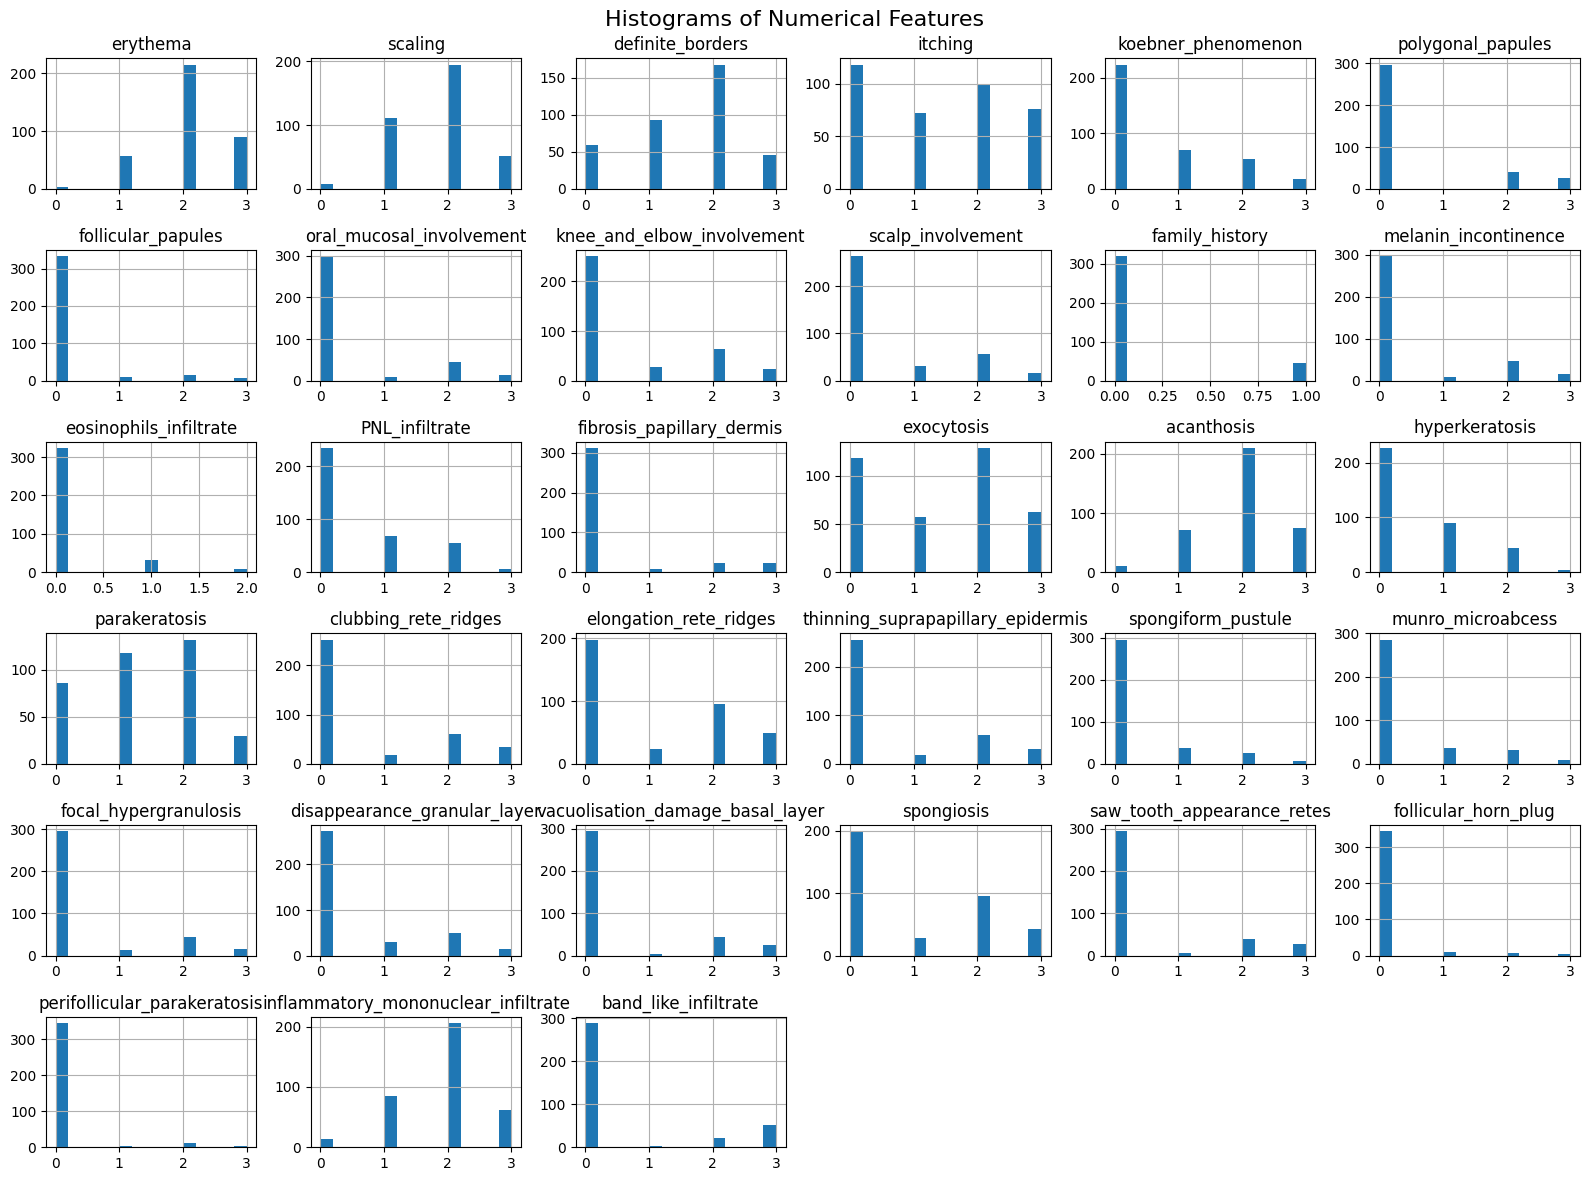

In [34]:
# plotting histograms

df[numeric_features].hist(
    figsize=(16, 12),
    bins=15
)

plt.suptitle(
    "Histograms of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

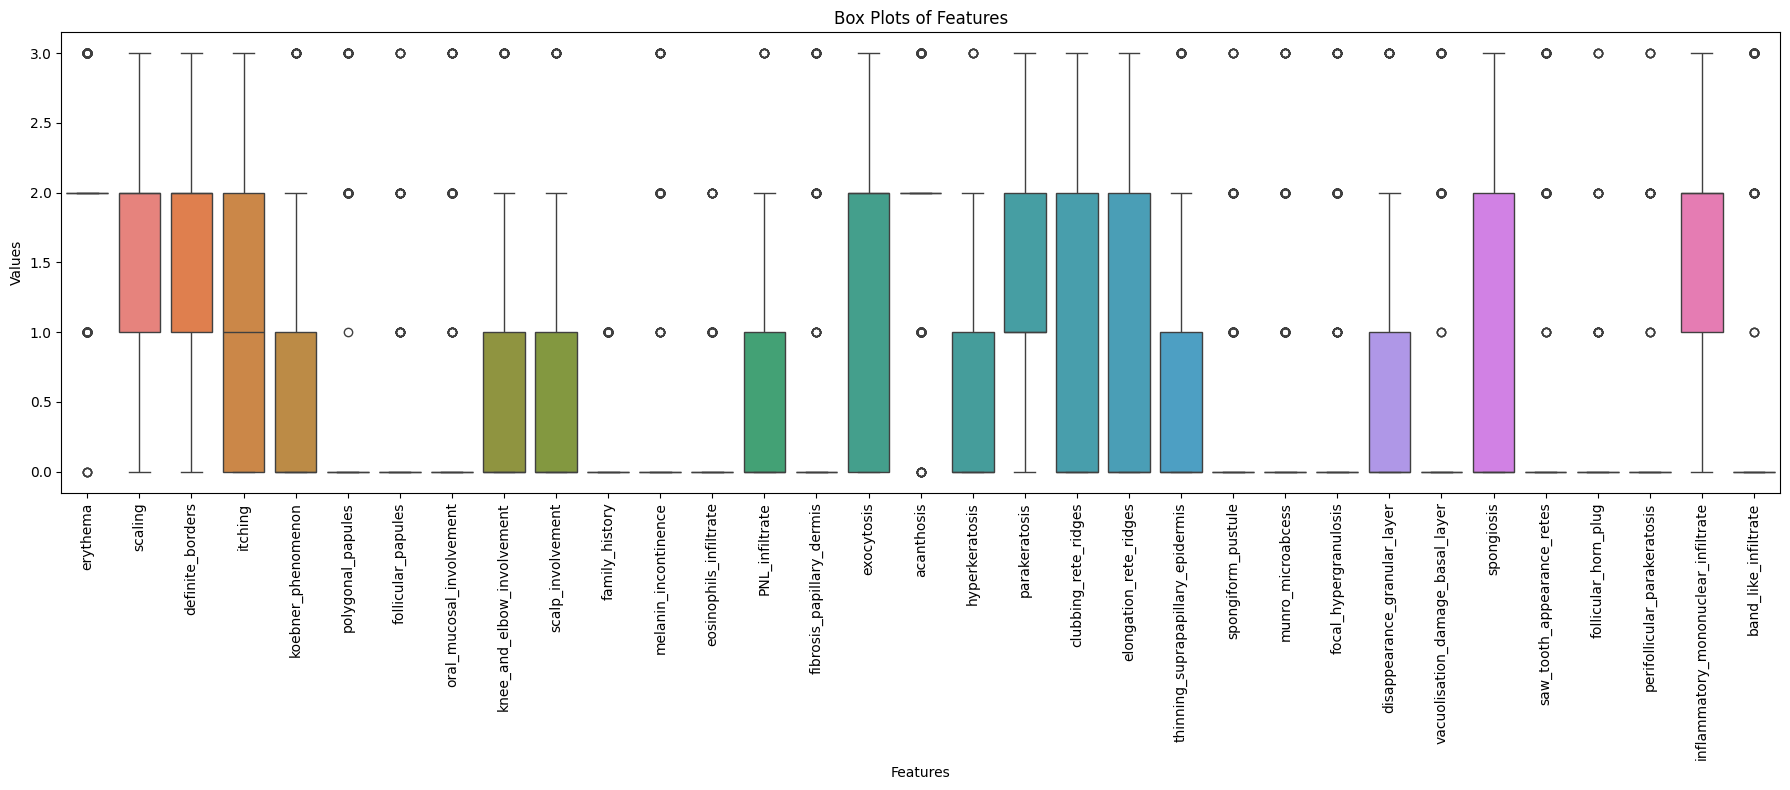

In [35]:
# box plots

plt.figure(figsize=(18, 8))

sns.boxplot(
    data=df[numeric_features]
)

plt.title("Box Plots of Features")
plt.xlabel("Features")
plt.ylabel("Values")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

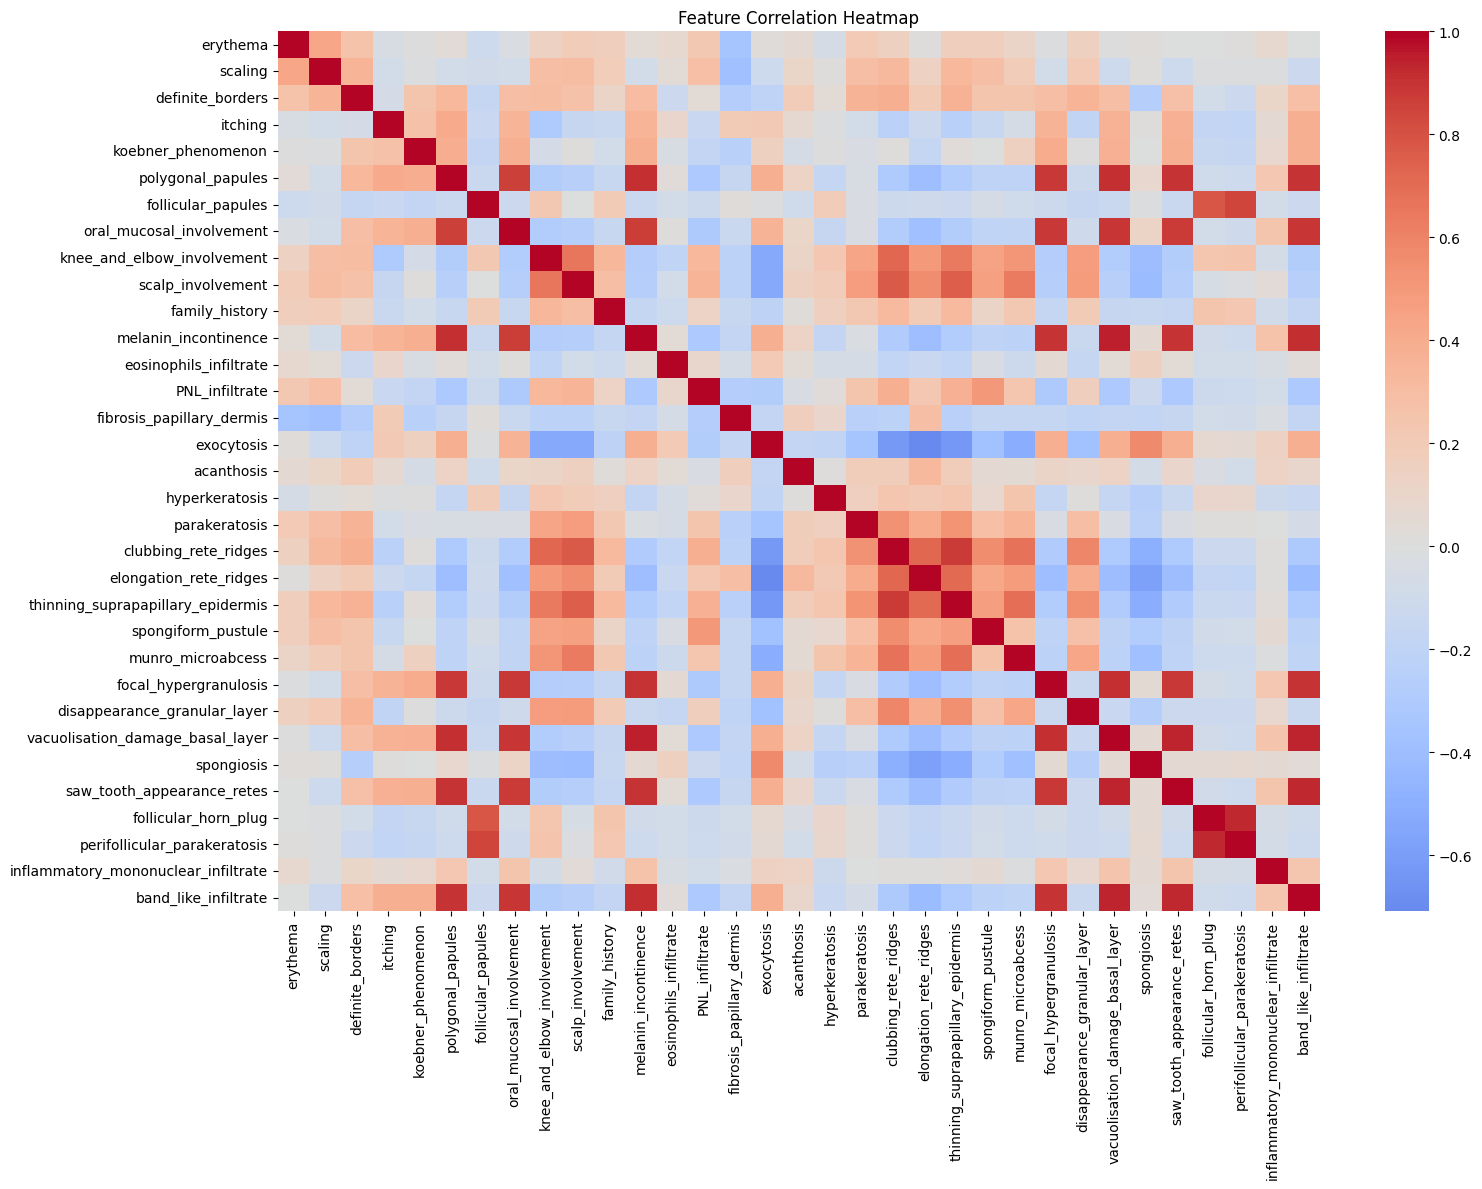

In [36]:
# correlation heatmap

correlation_matrix = df[numeric_features].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

The dataset has 366 records, 34 features, and 6 classes. The classes are not perfectly balanced; class 1 has substantially more samples while class 6 has fewer.

In [37]:
# DATA PREPROCESSING

X = df.drop(columns=["class"])

y = df["class"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (366, 34)
Target shape: (366,)


In [38]:
print("Classes:")
print(sorted(y.unique()))

Classes:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [39]:
# encoding target variables

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Original classes:")
print(label_encoder.classes_)

print("\nEncoded classes:")
print(np.unique(y_encoded))

Original classes:
[1 2 3 4 5 6]

Encoded classes:
[0 1 2 3 4 5]


In [40]:
# train-test split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 292
Testing samples: 74


In [41]:
# class distribution after split

print("Training class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training class distribution:
0    89
1    49
2    57
3    39
4    42
5    16
Name: count, dtype: int64

Testing class distribution:
0    23
1    12
2    15
3    10
4    10
5     4
Name: count, dtype: int64


In [42]:
# standardizing features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (292, 34)
Scaled testing data shape: (74, 34)


In [43]:
# MODEL TRAINING

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

In [47]:
# seperating X and y

X = df.drop(columns=["class"])
y = df["class"]

# Convert all feature columns to numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Convert target to integer
y = pd.to_numeric(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (366, 34)
y shape: (366,)


In [48]:
X = df.drop(columns=["class"])
y = df["class"]

# Convert all feature columns to numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Convert target to integer
y = pd.to_numeric(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (366, 34)
y shape: (366,)


In [49]:
# splitting data before imputing

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Encode target
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (292, 34)
Testing data: (74, 34)


In [50]:
# imputing missing values

from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)

X_test_imputed = imputer.transform(X_test)

print("Missing values handled successfully.")

Missing values handled successfully.


In [51]:
print("NaN values in training data:",
      np.isnan(X_train_imputed).sum())

print("NaN values in testing data:",
      np.isnan(X_test_imputed).sum())

NaN values in training data: 0
NaN values in testing data: 0


In [52]:
print("NaN values in training data:",
      np.isnan(X_train_imputed).sum())

print("NaN values in testing data:",
      np.isnan(X_test_imputed).sum())

NaN values in training data: 0
NaN values in testing data: 0


In [54]:
print("NaN values after scaling:")
print("Training:", np.isnan(X_train_scaled).sum())
print("Testing:", np.isnan(X_test_scaled).sum())

NaN values after scaling:
Training: 0
Testing: 0


In [55]:
# creating models

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

models = {

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    )
}

In [58]:
# training the models

trained_models = {}

for name, model in models.items():

    model.fit(
        X_train_scaled,
        y_train
    )

    trained_models[name] = model

    print(name, "training completed.")

KNN training completed.
Random Forest training completed.
Logistic Regression training completed.
SVM training completed.
Decision Tree training completed.


In [59]:
# making predictions

predictions = {}

probabilities = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test_scaled)

    y_prob = model.predict_proba(X_test_scaled)

    predictions[name] = y_pred

    probabilities[name] = y_prob

    print(name, "prediction completed.")

KNN prediction completed.
Random Forest prediction completed.
Logistic Regression prediction completed.
SVM prediction completed.
Decision Tree prediction completed.


In [60]:
# calculating acc, prec, f1

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name in trained_models:

    y_pred = predictions[name]

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

display(
    results_df.round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.9054,0.9193,0.9054,0.9081
1,Random Forest,0.9595,0.9607,0.9595,0.9595
2,Logistic Regression,0.9595,0.9688,0.9595,0.9606
3,SVM,0.9730,0.9775,0.9730,0.9730
4,Decision Tree,0.9595,0.9646,0.9595,0.9594


In [61]:
# class-wise prec, rec, f1

from sklearn.metrics import classification_report

for name in trained_models:

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            predictions[name],
            target_names=[
                str(c) for c in label_encoder.classes_
            ],
            zero_division=0
        )
    )


KNN
              precision    recall  f1-score   support

           1       1.00      0.96      0.98        23
           2       0.80      0.67      0.73        12
           3       1.00      0.93      0.97        15
           4       0.64      0.90      0.75        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.91        74
   macro avg       0.91      0.91      0.90        74
weighted avg       0.92      0.91      0.91        74


Random Forest
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.91      0.83      0.87        12
           3       1.00      1.00      1.00        15
           4       0.82      0.90      0.86        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   

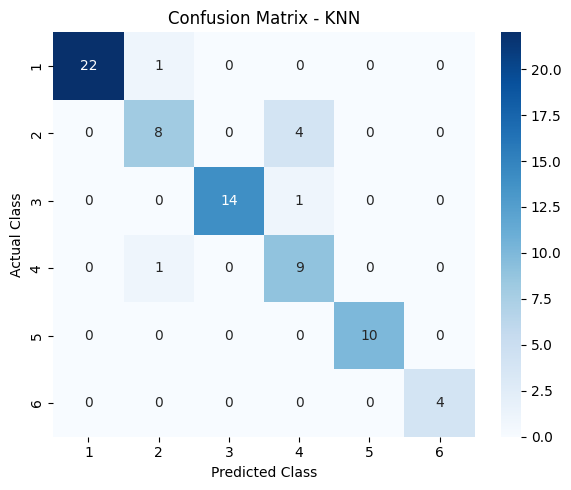

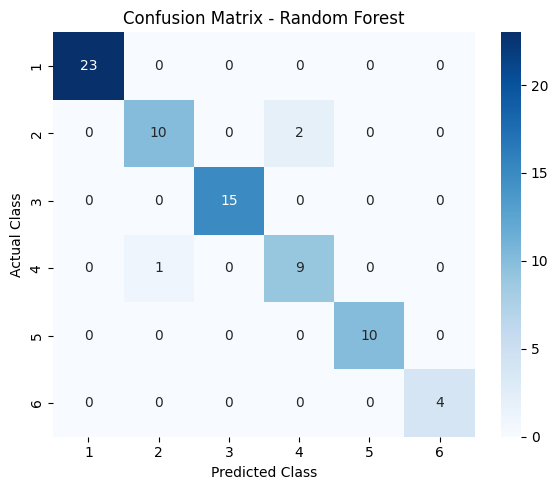

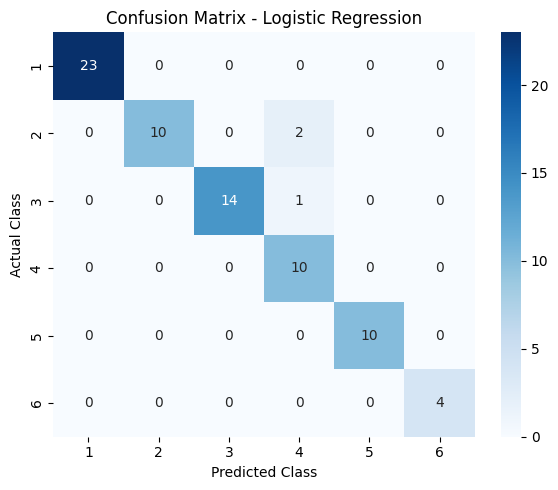

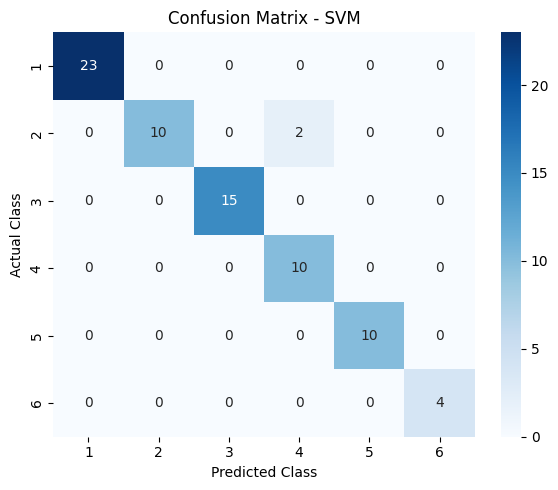

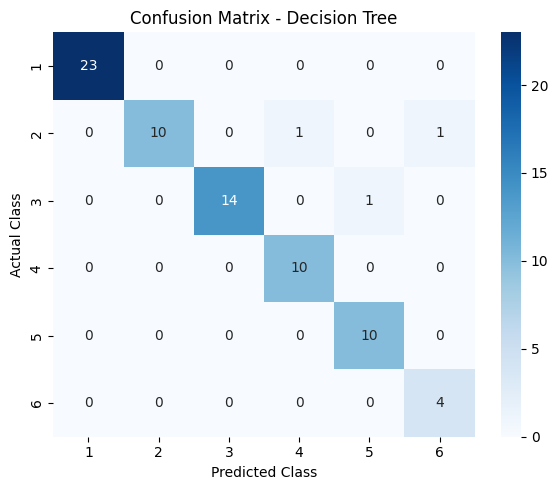

In [62]:
# confusion matrix for each model

from sklearn.metrics import confusion_matrix

class_names = [
    str(c) for c in label_encoder.classes_
]

for name in trained_models:

    cm = confusion_matrix(
        y_test,
        predictions[name]
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(
        f"Confusion Matrix - {name}"
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.tight_layout()
    plt.show()

In [63]:
# ROC-AUC

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

classes = np.unique(y_test)

y_test_binary = label_binarize(
    y_test,
    classes=classes
)

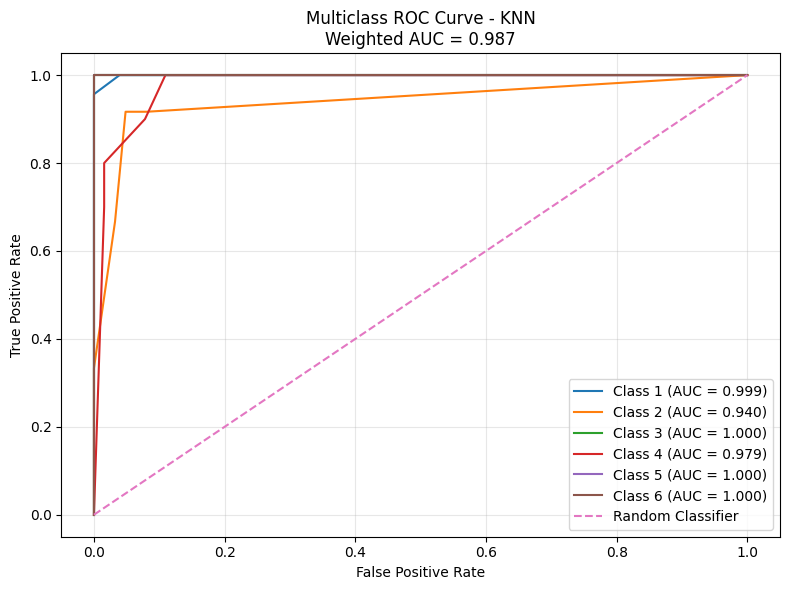

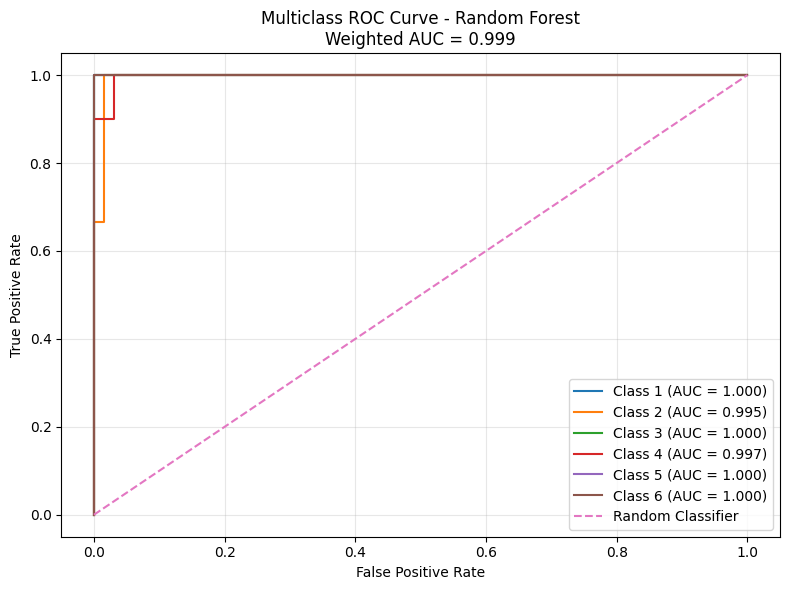

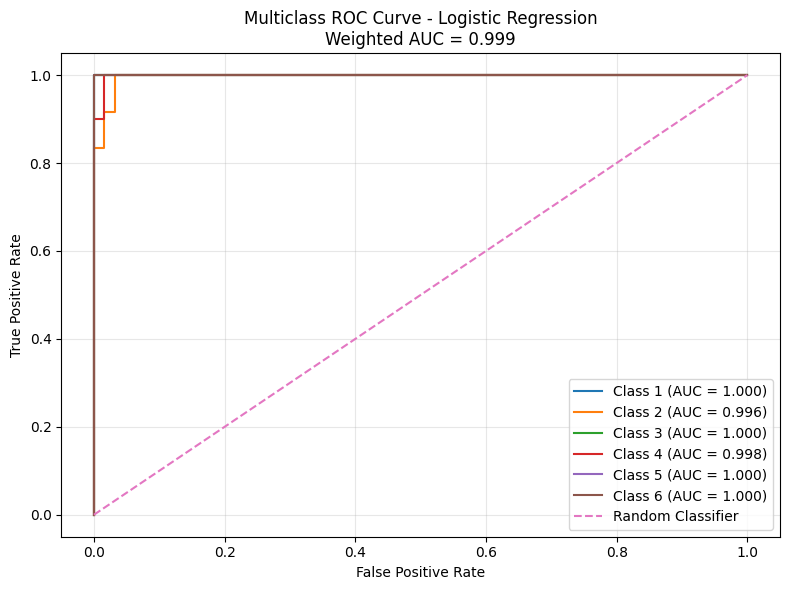

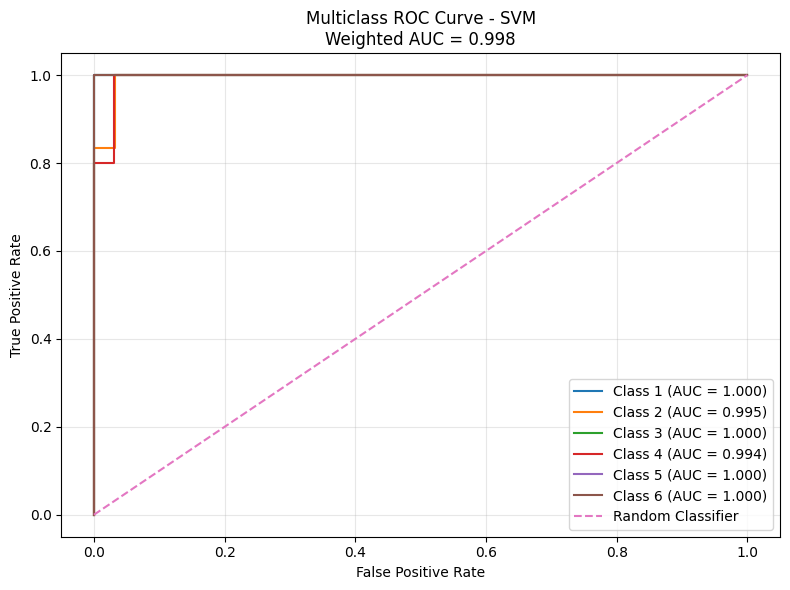

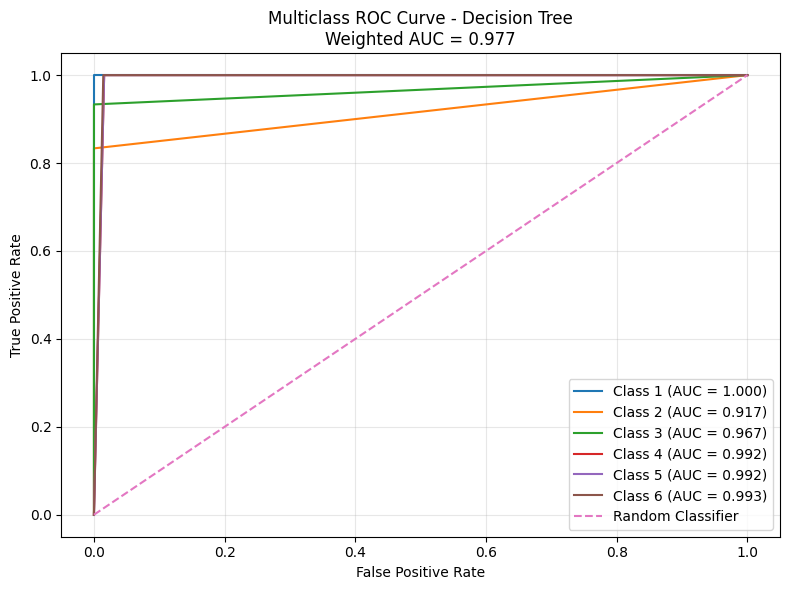

In [64]:
# ROC curve for all models

for name in trained_models:

    y_prob = probabilities[name]

    plt.figure(figsize=(8, 6))

    for i, class_label in enumerate(classes):

        fpr, tpr, thresholds = roc_curve(
            y_test_binary[:, i],
            y_prob[:, i]
        )

        roc_auc = auc(
            fpr,
            tpr
        )

        plt.plot(
            fpr,
            tpr,
            label=f"Class {label_encoder.classes_[i]} (AUC = {roc_auc:.3f})"
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random Classifier"
    )

    overall_auc = roc_auc_score(
        y_test,
        y_prob,
        multi_class="ovr",
        average="weighted"
    )

    plt.title(
        f"Multiclass ROC Curve - {name}\n"
        f"Weighted AUC = {overall_auc:.3f}"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

In [65]:
# ROC-AUC model comparison

auc_scores = []

for name in trained_models:

    y_prob = probabilities[name]

    auc_score = roc_auc_score(
        y_test,
        y_prob,
        multi_class="ovr",
        average="weighted"
    )

    auc_scores.append(auc_score)

results_df["ROC-AUC"] = auc_scores

display(
    results_df.round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,KNN,0.9054,0.9193,0.9054,0.9081,0.9871
1,Random Forest,0.9595,0.9607,0.9595,0.9595,0.9987
2,Logistic Regression,0.9595,0.9688,0.9595,0.9606,0.9991
3,SVM,0.9730,0.9775,0.9730,0.9730,0.9983
4,Decision Tree,0.9595,0.9646,0.9595,0.9594,0.9772


In [66]:
# m0dels by performance

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

display(
    results_df.round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,SVM,0.9730,0.9775,0.9730,0.9730,0.9983
2,Logistic Regression,0.9595,0.9688,0.9595,0.9606,0.9991
1,Random Forest,0.9595,0.9607,0.9595,0.9595,0.9987
4,Decision Tree,0.9595,0.9646,0.9595,0.9594,0.9772
0,KNN,0.9054,0.9193,0.9054,0.9081,0.9871


In [67]:
# best model

best_model_row = results_df.iloc[0]

print("Best Model:")
print(best_model_row["Model"])

print("\nPerformance:")

print(
    "Accuracy:",
    round(best_model_row["Accuracy"], 4)
)

print(
    "Precision:",
    round(best_model_row["Precision"], 4)
)

print(
    "Recall:",
    round(best_model_row["Recall"], 4)
)

print(
    "F1 Score:",
    round(best_model_row["F1 Score"], 4)
)

print(
    "ROC-AUC:",
    round(best_model_row["ROC-AUC"], 4)
)

Best Model:
SVM

Performance:
Accuracy: 0.973
Precision: 0.9775
Recall: 0.973
F1 Score: 0.973
ROC-AUC: 0.9983
